# Employee Attrition Prediction Using an Artificial Neural Network
**Mini Project — Neural Networks and Deep Learning**

**Student:** Relebohile Irene Lesitsi (25MDA10001)
**Programme:** MBA (Data Science and Artificial Intelligence), Chandigarh University

---
## Aim
To design, train, regularise and evaluate an Artificial Neural Network (ANN) that predicts whether an
employee will leave an organisation, extending the baseline network built in **Experiment 4**
(database connectivity and data preparation for a neural network).

## What this project adds to Experiment 4
1. Removes constant / identifier columns and prevents **data leakage** (scaler fitted on training data only).
2. Adds a **validation set** for early stopping, hyper-parameter selection and threshold selection.
3. Tackles the **class imbalance** (16 % of employees leave) with class weights.
4. Reduces over-fitting with **dropout, L2 regularisation and early stopping**.
5. Evaluates with metrics suitable for imbalanced data (precision, recall, F1, ROC-AUC, PR-AUC),
   repeated over **10 random seeds**, and compares with Logistic Regression and Random Forest.
6. Explains the ANN with **permutation feature importance**.

## 1. Importing libraries

In [1]:
import os, random, sqlite3, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import joblib
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             roc_curve, precision_recall_curve, classification_report)

sns.set_theme(style="whitegrid", font_scale=1.0)
BLUE, RED, GREY, GREEN, ORANGE = "#2F5D8C", "#C0392B", "#7F8C8D", "#2E8B57", "#E08E0B"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 220, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False})
os.makedirs("figures", exist_ok=True); os.makedirs("outputs", exist_ok=True); os.makedirs("models", exist_ok=True)

SEED = 42
SEEDS = [42, 1, 2, 3, 4, 5, 6, 7, 8, 9]          # 10 independent weight initialisations
def set_seed(s):
    random.seed(s); np.random.seed(s); tf.keras.utils.set_random_seed(s)
set_seed(SEED)

R = {}   # every number quoted in the report is stored here and saved to outputs/results.json
R["versions"] = {"python": __import__("platform").python_version(), "tensorflow": tf.__version__,
                 "keras": keras.__version__, "sklearn": sklearn.__version__,
                 "pandas": pd.__version__, "numpy": np.__version__}
print(R["versions"])

I0000 00:00:1792835514.661810    3180 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792835514.662462    3180 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792835517.021354    3180 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792835517.021862    3180 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


{'python': '3.12.3', 'tensorflow': '2.21.0', 'keras': '3.15.1', 'sklearn': '1.8.0', 'pandas': '3.0.2', 'numpy': '2.4.4'}


## 2. Data collection and database connectivity (SQLite)
The IBM HR Analytics Employee Attrition dataset (the same dataset used in Experiment 4) is stored in an
SQLite database and retrieved with an SQL query, exactly as in the class experiment.

In [2]:
CSV = "data/WA_Fn-UseC_-HR-Employee-Attrition.csv"
if not os.path.exists(CSV):          # makes the notebook run on Google Colab too
    import urllib.request
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve("https://raw.githubusercontent.com/IBM/employee-attrition-aif360/master/data/emp_attrition.csv", CSV)
raw = pd.read_csv(CSV, encoding="utf-8-sig")

connection = sqlite3.connect("employee_attrition.db")
raw.to_sql("EmployeeData", connection, if_exists="replace", index=False)
df = pd.read_sql_query("SELECT * FROM EmployeeData", connection)
print("Retrieved from database:", df.shape)

# An SQL aggregate query: attrition rate by department
sql_dept = pd.read_sql_query("""
    SELECT Department,
           COUNT(*) AS Employees,
           SUM(CASE WHEN Attrition='Yes' THEN 1 ELSE 0 END) AS Leavers,
           ROUND(100.0*SUM(CASE WHEN Attrition='Yes' THEN 1 ELSE 0 END)/COUNT(*),2) AS AttritionRatePct
    FROM EmployeeData GROUP BY Department ORDER BY AttritionRatePct DESC""", connection)
display(sql_dept)
connection.close()
R["sql_dept"] = sql_dept.to_dict(orient="records")
df.head()

Retrieved from database: (1470, 35)


,Department,Employees,Leavers,AttritionRatePct
0,Sales,446,92,20.63
1,Human Resources,63,12,19.05
2,Research & Development,961,133,13.84


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


## 3. Exploratory data analysis (EDA)

In [3]:
R["data"] = {"rows": int(df.shape[0]), "cols": int(df.shape[1]),
             "missing": int(df.isnull().sum().sum()), "duplicates": int(df.duplicated().sum())}
constant_cols = [c for c in df.columns if df[c].nunique() == 1]
R["data"]["constant_cols"] = constant_cols
R["data"]["num_features_raw"] = int(df.select_dtypes(include=["int64","float64"]).shape[1])
R["data"]["cat_features_raw"] = int(df.select_dtypes(include="object").shape[1])
print(R["data"])
counts = df["Attrition"].value_counts()
R["data"]["stay"], R["data"]["leave"] = int(counts["No"]), int(counts["Yes"])
R["data"]["leave_pct"] = round(100 * counts["Yes"] / len(df), 2)
print(counts.to_dict(), R["data"]["leave_pct"], "% leave")
df.describe().T.head(12)

{'rows': 1470, 'cols': 35, 'missing': 0, 'duplicates': 0, 'constant_cols': ['EmployeeCount', 'Over18', 'StandardHours'], 'num_features_raw': 26, 'cat_features_raw': 9}
{'No': 1233, 'Yes': 237} 16.12 % leave


,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


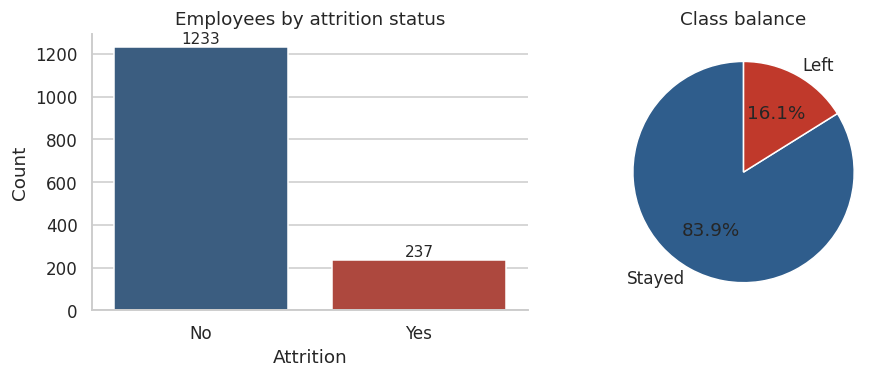

In [4]:
# Figure: class distribution
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
sns.countplot(x="Attrition", data=df, palette=[BLUE, RED], ax=ax[0], order=["No", "Yes"])
for p in ax[0].patches:
    ax[0].annotate(f"{int(p.get_height())}", (p.get_x()+p.get_width()/2, p.get_height()),
                   ha="center", va="bottom", fontsize=10)
ax[0].set_title("Employees by attrition status"); ax[0].set_xlabel("Attrition"); ax[0].set_ylabel("Count")
ax[1].pie(counts[["No", "Yes"]], labels=["Stayed", "Left"], autopct="%1.1f%%", colors=[BLUE, RED],
          startangle=90, wedgeprops={"edgecolor": "white"})
ax[1].set_title("Class balance")
plt.tight_layout(); plt.savefig("figures/fig_class_distribution.png"); plt.show()

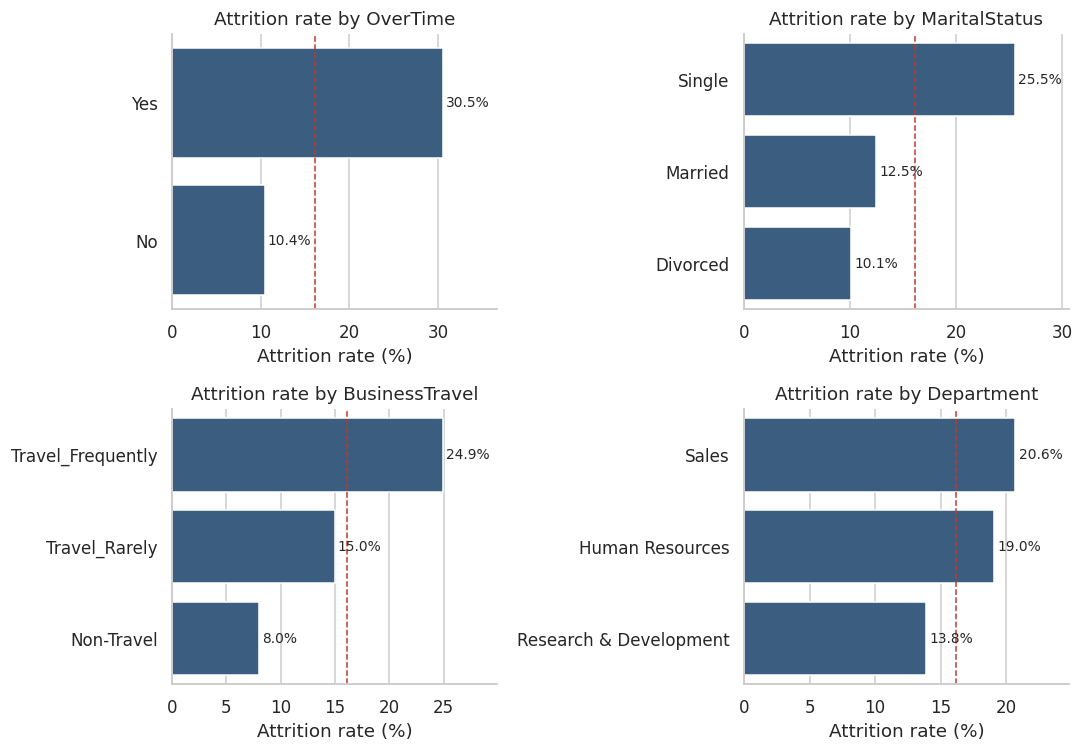

{'OverTime': {'Yes': 30.53, 'No': 10.44}, 'MaritalStatus': {'Single': 25.53, 'Married': 12.48, 'Divorced': 10.09}, 'BusinessTravel': {'Travel_Frequently': 24.91, 'Travel_Rarely': 14.96, 'Non-Travel': 8.0}, 'Department': {'Sales': 20.63, 'Human Resources': 19.05, 'Research & Development': 13.84}}


In [5]:
# Figure: attrition rate by key categorical variables
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
rates = {}
for ax, col in zip(axes.ravel(), ["OverTime", "MaritalStatus", "BusinessTravel", "Department"]):
    r = (df.groupby(col)["Attrition"].apply(lambda s: 100*(s == "Yes").mean())).sort_values(ascending=False)
    rates[col] = r.round(2).to_dict()
    sns.barplot(x=r.values, y=r.index, ax=ax, color=BLUE)
    for i, v in enumerate(r.values):
        ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=9)
    ax.axvline(100*(df.Attrition == "Yes").mean(), color=RED, ls="--", lw=1)
    ax.set_title(f"Attrition rate by {col}"); ax.set_xlabel("Attrition rate (%)"); ax.set_ylabel("")
    ax.set_xlim(0, max(r.values)*1.2)
plt.tight_layout(); plt.savefig("figures/fig_eda_categorical.png"); plt.show()
R["eda_rates"] = rates; print(rates)

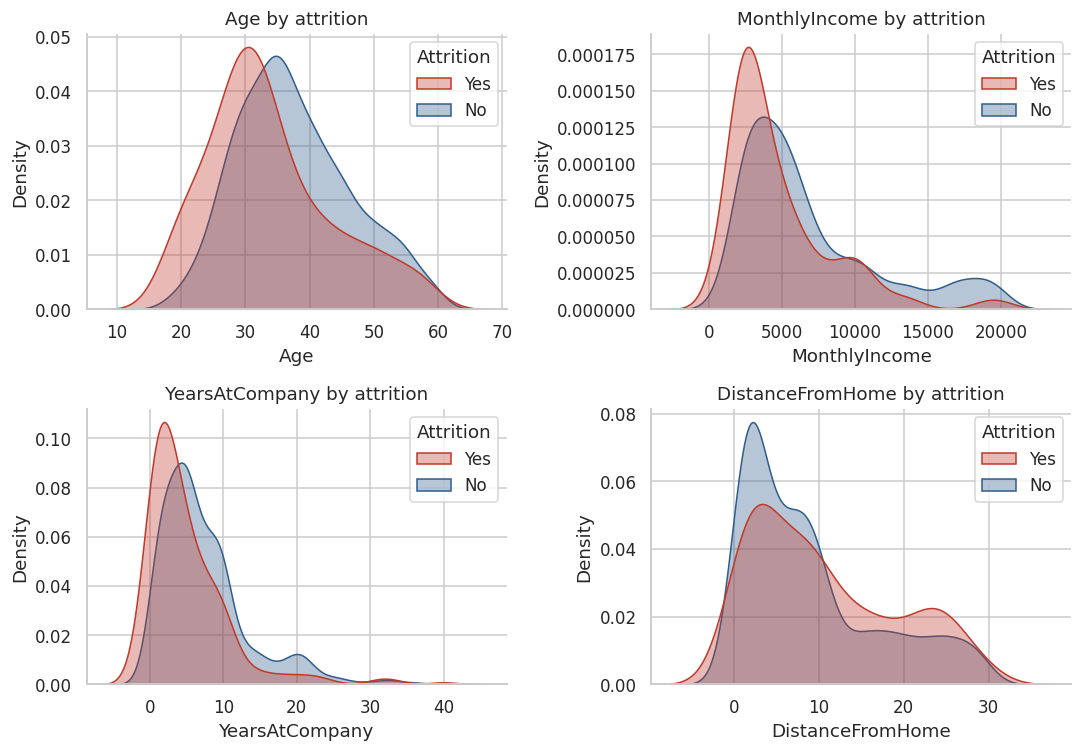

{'Age': {'stay': 36.0, 'leave': 32.0}, 'MonthlyIncome': {'stay': 5204.0, 'leave': 3202.0}, 'YearsAtCompany': {'stay': 6.0, 'leave': 3.0}, 'DistanceFromHome': {'stay': 7.0, 'leave': 9.0}, 'TotalWorkingYears': {'stay': 10.0, 'leave': 7.0}}


In [6]:
# Figure: numeric variables split by attrition
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, col in zip(axes.ravel(), ["Age", "MonthlyIncome", "YearsAtCompany", "DistanceFromHome"]):
    sns.kdeplot(data=df, x=col, hue="Attrition", fill=True, common_norm=False,
                palette={"No": BLUE, "Yes": RED}, ax=ax, alpha=0.35)
    ax.set_title(f"{col} by attrition")
plt.tight_layout(); plt.savefig("figures/fig_eda_numeric.png"); plt.show()
R["eda_medians"] = {c: {"stay": float(df.loc[df.Attrition=="No", c].median()),
                        "leave": float(df.loc[df.Attrition=="Yes", c].median())}
                    for c in ["Age", "MonthlyIncome", "YearsAtCompany", "DistanceFromHome", "TotalWorkingYears"]}
print(R["eda_medians"])

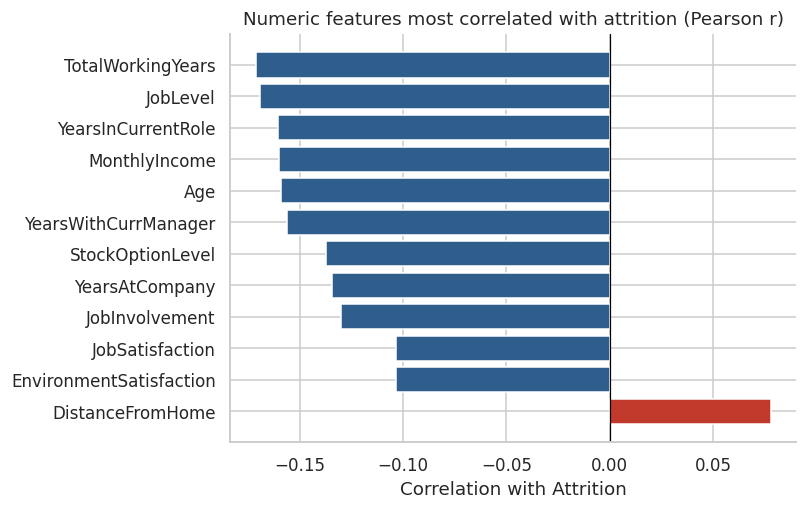

{'TotalWorkingYears': -0.171, 'JobLevel': -0.169, 'YearsInCurrentRole': -0.161, 'MonthlyIncome': -0.16, 'Age': -0.159, 'YearsWithCurrManager': -0.156, 'StockOptionLevel': -0.137, 'YearsAtCompany': -0.134, 'JobInvolvement': -0.13, 'JobSatisfaction': -0.103, 'EnvironmentSatisfaction': -0.103, 'DistanceFromHome': 0.078}


In [7]:
# Figure: correlation of numeric features with attrition
tmp = df.copy(); tmp["Attrition_bin"] = (tmp["Attrition"] == "Yes").astype(int)
num = tmp.select_dtypes(include=["int64", "float64"]).drop(columns=["EmployeeCount", "StandardHours", "EmployeeNumber"])
corr = num.corr()["Attrition_bin"].drop("Attrition_bin")
top = corr.reindex(corr.abs().sort_values(ascending=False).index).head(12).iloc[::-1]
plt.figure(figsize=(7.5, 4.8))
plt.barh(top.index, top.values, color=[RED if v > 0 else BLUE for v in top.values])
plt.axvline(0, color="black", lw=0.8)
plt.title("Numeric features most correlated with attrition (Pearson r)")
plt.xlabel("Correlation with Attrition"); plt.tight_layout()
plt.savefig("figures/fig_correlation.png"); plt.show()
R["top_corr"] = {k: round(float(v), 3) for k, v in top.iloc[::-1].items()}
print(R["top_corr"])

## 4. Data preprocessing
* Remove **constant columns** (`EmployeeCount`, `Over18`, `StandardHours`) — they carry no information.
* Remove the **identifier** `EmployeeNumber` — it would let a network memorise individuals.
* One-hot encode categorical features (`drop_first=True`), map `Attrition` → 1 (left) / 0 (stayed).
* **Split first, scale afterwards**: the `StandardScaler` is fitted on training rows only, so no statistics
  from validation/test rows leak into training (Experiment 4 scaled the full dataset before splitting).

In [8]:
drop_cols = constant_cols + ["EmployeeNumber"]
data = df.drop(columns=drop_cols).copy()
y = (data.pop("Attrition") == "Yes").astype(int)
cat_cols = data.select_dtypes(include="object").columns.tolist()
num_cols = [c for c in data.columns if c not in cat_cols]
X = pd.get_dummies(data, columns=cat_cols, drop_first=True).astype(float)
R["prep"] = {"dropped": drop_cols, "n_cat": len(cat_cols), "n_num": len(num_cols), "n_features": int(X.shape[1]),
             "cat_cols": cat_cols}
print(R["prep"])

# 80:20 stratified train/test (same ratio and random_state as Experiment 4) ...
X_tr_full, X_te, y_tr_full, y_te = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)
# ... then 80:20 stratified train/validation inside the training portion
X_tr, X_va, y_tr, y_va = train_test_split(X_tr_full, y_tr_full, test_size=0.20, random_state=SEED, stratify=y_tr_full)

scaler = StandardScaler().fit(X_tr)                   # fitted on TRAIN only
Xtr, Xva, Xte = (scaler.transform(a).astype("float32") for a in (X_tr, X_va, X_te))
ytr, yva, yte = y_tr.values, y_va.values, y_te.values

R["split"] = {"train": len(ytr), "val": len(yva), "test": len(yte),
              "train_pos": int(ytr.sum()), "val_pos": int(yva.sum()), "test_pos": int(yte.sum())}
print(R["split"])

n0, n1 = (ytr == 0).sum(), (ytr == 1).sum()
CLASS_WEIGHT = {0: len(ytr) / (2 * n0), 1: len(ytr) / (2 * n1)}
R["class_weight"] = {k: round(float(v), 3) for k, v in CLASS_WEIGHT.items()}
print("class weights:", R["class_weight"])

{'dropped': ['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber'], 'n_cat': 7, 'n_num': 23, 'n_features': 44, 'cat_cols': ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']}
{'train': 940, 'val': 236, 'test': 294, 'train_pos': 152, 'val_pos': 38, 'test_pos': 47}
class weights: {0: 0.596, 1: 3.092}


## 5. Helper functions: metrics, threshold selection, ANN builders

In [9]:
def metrics(y_true, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    return dict(accuracy=accuracy_score(y_true, pred),
                precision=precision_score(y_true, pred, zero_division=0),
                recall=recall_score(y_true, pred),
                f1=f1_score(y_true, pred),
                roc_auc=roc_auc_score(y_true, prob),
                pr_auc=average_precision_score(y_true, prob))

def best_threshold(y_true, prob):
    """Threshold that maximises F1 on the VALIDATION set (never on the test set)."""
    grid = np.arange(0.05, 0.96, 0.01)
    f1s = [f1_score(y_true, (prob >= t).astype(int), zero_division=0) for t in grid]
    return float(grid[int(np.argmax(f1s))]), grid, np.array(f1s)

def build_baseline(input_dim):
    """Exactly the architecture used in Experiment 4: 64-32-8-16-1, no regularisation."""
    return keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(64, activation="relu"), layers.Dense(32, activation="relu"),
        layers.Dense(8, activation="relu"), layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid")], name="baseline_ann_exp4")

def build_regularised(input_dim, units=(64, 32, 16), dropout=0.3, l2=1e-3):
    ls = [layers.Input(shape=(input_dim,))]
    for u in units:
        ls += [layers.Dense(u, activation="relu", kernel_regularizer=regularizers.l2(l2)), layers.Dropout(dropout)]
    ls += [layers.Dense(1, activation="sigmoid")]
    return keras.Sequential(ls, name="regularised_ann")

def compile_fit(model, epochs, early_stop, class_weight, seed, lr=1e-3):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])
    cb = [keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=20,
                                        restore_best_weights=True)] if early_stop else []
    hist = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=epochs, batch_size=32,
                     class_weight=class_weight, callbacks=cb, verbose=0, shuffle=True)
    return hist

VARIANTS = {
    "V0 Baseline ANN (Experiment 4 setup)":        dict(kind="baseline", epochs=30,  es=False, cw=None),
    "V1 + Early stopping":                          dict(kind="baseline", epochs=200, es=True,  cw=None),
    "V2 + Dropout and L2 regularisation":           dict(kind="reg",      epochs=200, es=True,  cw=None),
    "V3 + Class weights (final ANN)":               dict(kind="reg",      epochs=200, es=True,  cw=CLASS_WEIGHT),
}
D = Xtr.shape[1]
print("Input dimension:", D)

Input dimension: 44


## 6. Hyper-parameter selection (validation set only)
A small grid over network width, dropout rate and L2 strength is evaluated with three seeds each;
the configuration with the highest **mean validation ROC-AUC** is chosen. The test set is not touched.

In [10]:
grid_rows = []
t0 = time.time()
for units in [(32, 16), (64, 32, 16), (128, 64, 32)]:
    for dropout in [0.2, 0.3, 0.5]:
        for l2 in [1e-4, 1e-3, 1e-2]:
            aucs = []
            for s in [42, 1, 2]:
                set_seed(s)
                m = build_regularised(D, units, dropout, l2)
                compile_fit(m, 200, True, CLASS_WEIGHT, s)
                aucs.append(roc_auc_score(yva, m.predict(Xva, verbose=0).ravel()))
                keras.backend.clear_session()
            grid_rows.append(dict(units=str(units), dropout=dropout, l2=l2,
                                  val_auc_mean=np.mean(aucs), val_auc_std=np.std(aucs)))
grid = pd.DataFrame(grid_rows).sort_values("val_auc_mean", ascending=False).reset_index(drop=True)
print(f"Grid search finished in {time.time()-t0:.0f}s")
display(grid.head(10))
best = grid.iloc[0]
BEST_UNITS = eval(best["units"]); BEST_DROP = float(best["dropout"]); BEST_L2 = float(best["l2"])
R["grid"] = {"n_configs": len(grid), "best": dict(units=list(BEST_UNITS), dropout=BEST_DROP, l2=BEST_L2,
             val_auc=round(float(best["val_auc_mean"]), 4)),
             "top5": grid.head(5).round(4).to_dict(orient="records"),
             "worst_val_auc": round(float(grid["val_auc_mean"].min()), 4),
             "best_val_auc": round(float(grid["val_auc_mean"].max()), 4)}
grid.to_csv("outputs/grid_search_results.csv", index=False)
print(R["grid"]["best"])

Grid search finished in 878s


,units,dropout,l2,val_auc_mean,val_auc_std
0,"(64, 32, 16)",0.5,0.0100,0.832403,0.008628
1,"(64, 32, 16)",0.3,0.0001,0.831517,0.005961
2,"(64, 32, 16)",0.3,0.0010,0.831384,0.003778
3,"(64, 32, 16)",0.3,0.0100,0.830232,0.004558
4,"(64, 32, 16)",0.5,0.0001,0.829257,0.001918
5,"(64, 32, 16)",0.5,0.0010,0.827795,0.008108
6,"(64, 32, 16)",0.2,0.0001,0.825625,0.003694
7,"(64, 32, 16)",0.2,0.0010,0.824739,0.003919
8,"(64, 32, 16)",0.2,0.0100,0.824517,0.002214
9,"(128, 64, 32)",0.3,0.0001,0.822346,0.000439


{'units': [64, 32, 16], 'dropout': 0.5, 'l2': 0.01, 'val_auc': 0.8324}


## 7. Ablation study: from the Experiment 4 baseline to the final ANN
Each variant adds one improvement and is trained with **10 different random seeds**.
Seed 42 is designated in advance as the representative run used for the figures.

In [11]:
def make_model(cfg):
    if cfg["kind"] == "baseline":
        return build_baseline(D)
    return build_regularised(D, BEST_UNITS, BEST_DROP, BEST_L2)

store = {}          # store[variant][seed] = dict(val_prob, test_prob, history, epochs_run)
abl_rows = []
t0 = time.time()
for name, cfg in VARIANTS.items():
    store[name] = {}
    for s in SEEDS:
        set_seed(s)
        m = make_model(cfg)
        h = compile_fit(m, cfg["epochs"], cfg["es"], cfg["cw"], s)
        pv, pt = m.predict(Xva, verbose=0).ravel(), m.predict(Xte, verbose=0).ravel()
        store[name][s] = dict(val=pv, test=pt, hist=h.history, epochs=len(h.history["loss"]))
        if s == SEED and name.startswith("V3"):
            final_model = m                       # keep the representative final network
        elif s == SEED and name.startswith("V0"):
            baseline_model = m
        row = metrics(yte, pt, 0.5); row.update(variant=name, seed=s, epochs=store[name][s]["epochs"])
        abl_rows.append(row)
print(f"Ablation finished in {time.time()-t0:.0f}s")
abl = pd.DataFrame(abl_rows)
summary = abl.groupby("variant", sort=False)[["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "epochs"]].agg(["mean", "std"])
display(summary.round(3))

Ablation finished in 410s


accuracy        precision        recall  \
                                         mean    std      mean    std   mean   
variant                                                                        
V0 Baseline ANN (Experiment 4 setup)    0.834  0.018     0.486  0.064  0.400   
V1 + Early stopping                     0.852  0.009     0.557  0.219  0.272   
V2 + Dropout and L2 regularisation      0.857  0.015     0.416  0.360  0.200   
V3 + Class weights (final ANN)          0.746  0.076     0.360  0.047  0.664   

                                                f1        roc_auc         \
                                        std   mean    std    mean    std   
variant                                                                    
V0 Baseline ANN (Experiment 4 setup)  0.061  0.435  0.044   0.724  0.030   
V1 + Early stopping                   0.165  0.339  0.172   0.751  0.017   
V2 + Dropout and L2 regularisation    0.176  0.268  0.233   0.765  0.016   
V3 + Class weights (final ANN)        0.087  0.461  0.035   0.759  0.012   

                                     pr_auc        epochs          
                                       mean    std   mean     std  
variant                                                            
V0 Baseline ANN (Experiment 4 setup)  0.468  0.018   30.0   0.000  
V1 + Early stopping                   0.489  0.031   29.3   5.478  
V2 + Dropout and L2 regularisation    0.524  0.048   54.1  14.693  
V3 + Class weights (final ANN)        0.520  0.038   46.6  10.731

In [12]:
# Add V4: final ANN + validation-tuned decision threshold
v3 = [k for k in VARIANTS if k.startswith("V3")][0]
v4_rows, thr_by_seed = [], {}
for s in SEEDS:
    thr, _, _ = best_threshold(yva, store[v3][s]["val"])
    thr_by_seed[s] = thr
    r = metrics(yte, store[v3][s]["test"], thr); r.update(variant="V4 + Tuned decision threshold", seed=s,
                                                           epochs=store[v3][s]["epochs"])
    v4_rows.append(r)
abl_all = pd.concat([abl, pd.DataFrame(v4_rows)], ignore_index=True)
ablation = abl_all.groupby("variant", sort=False)[["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]].agg(["mean", "std"])
display(ablation.round(3))
R["ablation"] = {}
for v in abl_all["variant"].unique():
    sub = abl_all[abl_all.variant == v]
    R["ablation"][v] = {m: [round(float(sub[m].mean()), 4), round(float(sub[m].std()), 4)]
                        for m in ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]}
    R["ablation"][v]["epochs_mean"] = round(float(sub["epochs"].mean()), 1)
R["thresholds_by_seed"] = {int(k): round(v, 2) for k, v in thr_by_seed.items()}
print(R["thresholds_by_seed"])
abl_all.to_csv("outputs/ablation_all_seeds.csv", index=False)

accuracy        precision        recall  \
                                         mean    std      mean    std   mean   
variant                                                                        
V0 Baseline ANN (Experiment 4 setup)    0.834  0.018     0.486  0.064  0.400   
V1 + Early stopping                     0.852  0.009     0.557  0.219  0.272   
V2 + Dropout and L2 regularisation      0.857  0.015     0.416  0.360  0.200   
V3 + Class weights (final ANN)          0.746  0.076     0.360  0.047  0.664   
V4 + Tuned decision threshold           0.849  0.013     0.535  0.046  0.468   

                                                f1        roc_auc         \
                                        std   mean    std    mean    std   
variant                                                                    
V0 Baseline ANN (Experiment 4 setup)  0.061  0.435  0.044   0.724  0.030   
V1 + Early stopping                   0.165  0.339  0.172   0.751  0.017   
V2 + Dropout and L2 regularisation    0.176  0.268  0.233   0.765  0.016   
V3 + Class weights (final ANN)        0.087  0.461  0.035   0.759  0.012   
V4 + Tuned decision threshold         0.051  0.497  0.036   0.759  0.012   

                                     pr_auc         
                                       mean    std  
variant                                             
V0 Baseline ANN (Experiment 4 setup)  0.468  0.018  
V1 + Early stopping                   0.489  0.031  
V2 + Dropout and L2 regularisation    0.524  0.048  
V3 + Class weights (final ANN)        0.520  0.038  
V4 + Tuned decision threshold         0.520  0.038

{42: 0.7, 1: 0.56, 2: 0.62, 3: 0.66, 4: 0.65, 5: 0.78, 6: 0.76, 7: 0.69, 8: 0.71, 9: 0.8}


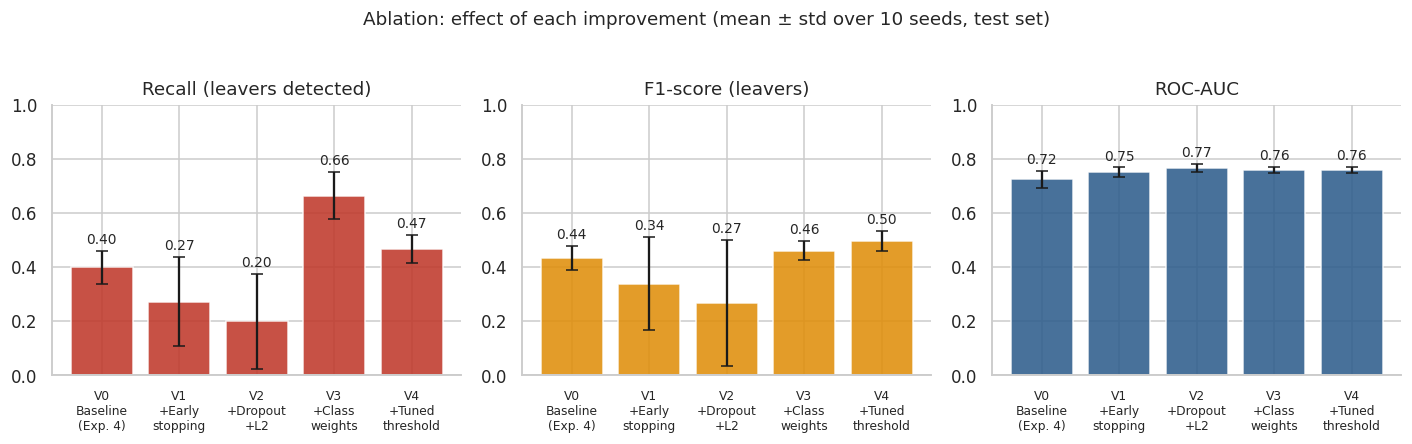

In [13]:
# Figure: ablation (mean +/- std over 10 seeds)
order = list(abl_all["variant"].unique())
short = ["V0\nBaseline\n(Exp. 4)", "V1\n+Early\nstopping", "V2\n+Dropout\n+L2", "V3\n+Class\nweights", "V4\n+Tuned\nthreshold"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
for ax, (m, title, col) in zip(axes, [("recall", "Recall (leavers detected)", RED), ("f1", "F1-score (leavers)", ORANGE),
                                      ("roc_auc", "ROC-AUC", BLUE)]):
    means = [abl_all[abl_all.variant == v][m].mean() for v in order]
    stds = [abl_all[abl_all.variant == v][m].std() for v in order]
    ax.bar(range(5), means, yerr=stds, capsize=4, color=col, alpha=0.88)
    for i, v in enumerate(means):
        ax.text(i, v + 0.025 + stds[i], f"{v:.2f}", ha="center", fontsize=9)
    ax.set_xticks(range(5)); ax.set_xticklabels(short, fontsize=8); ax.set_ylim(0, 1.0); ax.set_title(title)
plt.suptitle("Ablation: effect of each improvement (mean ± std over 10 seeds, test set)", y=1.03, fontsize=12)
plt.tight_layout(); plt.savefig("figures/fig_ablation.png"); plt.show()

## 8. Comparison with classical models
Logistic Regression and Random Forest are trained on the same training rows (with balanced class weights)
and evaluated on the same test set. Random Forest is repeated over the same 10 seeds.

In [14]:
lr = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED).fit(Xtr, ytr)
lr_val, lr_test = lr.predict_proba(Xva)[:, 1], lr.predict_proba(Xte)[:, 1]

rf_rows, rf_store = [], {}
for s in SEEDS:
    rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight="balanced",
                                random_state=s, n_jobs=-1).fit(Xtr, ytr)
    rf_store[s] = (rf.predict_proba(Xva)[:, 1], rf.predict_proba(Xte)[:, 1])
    r = metrics(yte, rf_store[s][1], 0.5); r["seed"] = s; rf_rows.append(r)
rf_df = pd.DataFrame(rf_rows)

def agg(df_, cols=("accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc")):
    return {m: [round(float(df_[m].mean()), 4), round(float(df_[m].std()) if len(df_) > 1 else 0.0, 4)] for m in cols}

v0 = [k for k in VARIANTS if k.startswith("V0")][0]
comparison = {
    "Logistic Regression": agg(pd.DataFrame([metrics(yte, lr_test, 0.5)])),
    "Random Forest": agg(rf_df),
    "Baseline ANN (Exp. 4 setup)": R["ablation"][v0],
    "Final ANN (V3, threshold 0.5)": R["ablation"][v3],
    "Final ANN (V4, tuned threshold)": R["ablation"]["V4 + Tuned decision threshold"],
}
# tuned-threshold versions of the classical models (for a fair comparison)
lr_thr, _, _ = best_threshold(yva, lr_val)
comparison["Logistic Regression (tuned threshold)"] = agg(pd.DataFrame([metrics(yte, lr_test, lr_thr)]))
rf_t = []
for s in SEEDS:
    t, _, _ = best_threshold(yva, rf_store[s][0]); rf_t.append(metrics(yte, rf_store[s][1], t))
comparison["Random Forest (tuned threshold)"] = agg(pd.DataFrame(rf_t))
R["comparison"] = comparison
R["lr_threshold"] = round(lr_thr, 2)
cmp_df = pd.DataFrame({k: {m: f"{v[m][0]:.3f} ± {v[m][1]:.3f}" for m in ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]}
                       for k, v in comparison.items()}).T
display(cmp_df)
cmp_df.to_csv("outputs/model_comparison.csv")

,accuracy,precision,recall,f1,roc_auc,pr_auc
Logistic Regression,0.775 ± 0.000,0.386 ± 0.000,0.681 ± 0.000,0.492 ± 0.000,0.789 ± 0.000,0.536 ± 0.000
Random Forest,0.830 ± 0.003,0.379 ± 0.028,0.096 ± 0.011,0.153 ± 0.015,0.754 ± 0.007,0.371 ± 0.009
Baseline ANN (Exp. 4 setup),0.834 ± 0.018,0.486 ± 0.064,0.400 ± 0.061,0.435 ± 0.044,0.724 ± 0.030,0.468 ± 0.018
"Final ANN (V3, threshold 0.5)",0.746 ± 0.076,0.360 ± 0.047,0.664 ± 0.087,0.461 ± 0.035,0.758 ± 0.012,0.520 ± 0.038
"Final ANN (V4, tuned threshold)",0.849 ± 0.013,0.535 ± 0.046,0.468 ± 0.051,0.497 ± 0.036,0.758 ± 0.012,0.520 ± 0.038
Logistic Regression (tuned threshold),0.823 ± 0.000,0.451 ± 0.000,0.489 ± 0.000,0.469 ± 0.000,0.789 ± 0.000,0.536 ± 0.000
Random Forest (tuned threshold),0.806 ± 0.011,0.392 ± 0.020,0.379 ± 0.054,0.383 ± 0.028,0.754 ± 0.007,0.371 ± 0.009


## 9. Representative final model (seed 42): curves, confusion matrix, ROC and PR

In [15]:
final_prob_val = store[v3][SEED]["val"]; final_prob_te = store[v3][SEED]["test"]
THR = best_threshold(yva, final_prob_val)[0]
R["final"] = {"threshold": round(THR, 2), "epochs_run": store[v3][SEED]["epochs"],
              "baseline_epochs": store[v0][SEED]["epochs"]}
R["final"]["at_0.5"] = {k: round(float(v), 4) for k, v in metrics(yte, final_prob_te, 0.5).items()}
R["final"]["at_thr"] = {k: round(float(v), 4) for k, v in metrics(yte, final_prob_te, THR).items()}
R["baseline_seed42"] = {k: round(float(v), 4) for k, v in metrics(yte, store[v0][SEED]["test"], 0.5).items()}
print(R["final"]); print(R["baseline_seed42"])

fm_params = final_model.count_params(); bm_params = baseline_model.count_params()
R["params"] = {"baseline": int(bm_params), "final": int(fm_params)}
R["final"]["val_auc"] = round(float(roc_auc_score(yva, final_prob_val)), 4)
final_model.summary()

{'threshold': 0.7, 'epochs_run': 38, 'baseline_epochs': 30, 'at_0.5': {'accuracy': 0.7653, 'precision': 0.369, 'recall': 0.6596, 'f1': 0.4733, 'roc_auc': 0.7402, 'pr_auc': 0.4914}, 'at_thr': {'accuracy': 0.8435, 'precision': 0.5135, 'recall': 0.4043, 'f1': 0.4524, 'roc_auc': 0.7402, 'pr_auc': 0.4914}}
{'accuracy': 0.8537, 'precision': 0.5556, 'recall': 0.4255, 'f1': 0.4819, 'roc_auc': 0.7207, 'pr_auc': 0.4807}


Model: "regularised_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_140 (Dense)               │ (None, 64)             │         2,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_30 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_141 (Dense)               │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_31 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_142 (Dense)               │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_32 (Dropout)            │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_143 (Dense)               │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,517 (64.52 KB)

 Trainable params: 5,505 (21.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 11,012 (43.02 KB)

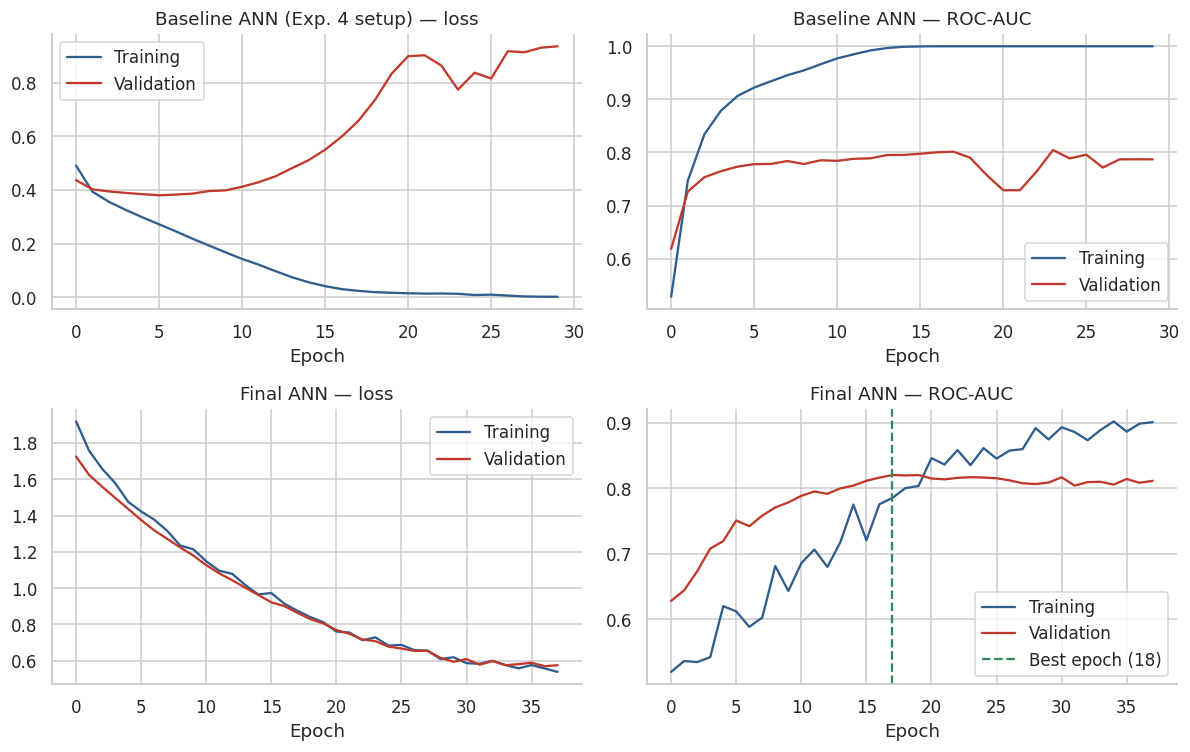

{'baseline_final_train_loss': 0.0015, 'baseline_final_val_loss': 0.9362, 'baseline_min_val_loss': 0.3803, 'baseline_min_val_epoch': 6, 'baseline_final_train_auc': 1.0, 'baseline_final_val_auc': 0.787, 'final_best_epoch': 18, 'final_train_auc_at_best': 0.7856, 'final_val_auc_at_best': 0.8205}


In [16]:
# Figure: training behaviour, baseline vs final
hb, hf = store[v0][SEED]["hist"], store[v3][SEED]["hist"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
axes[0, 0].plot(hb["loss"], color=BLUE, label="Training"); axes[0, 0].plot(hb["val_loss"], color=RED, label="Validation")
axes[0, 0].set_title("Baseline ANN (Exp. 4 setup) — loss"); axes[0, 0].set_xlabel("Epoch"); axes[0, 0].legend()
axes[0, 1].plot(hb["auc"], color=BLUE, label="Training"); axes[0, 1].plot(hb["val_auc"], color=RED, label="Validation")
axes[0, 1].set_title("Baseline ANN — ROC-AUC"); axes[0, 1].set_xlabel("Epoch"); axes[0, 1].legend()
axes[1, 0].plot(hf["loss"], color=BLUE, label="Training"); axes[1, 0].plot(hf["val_loss"], color=RED, label="Validation")
axes[1, 0].set_title("Final ANN — loss"); axes[1, 0].set_xlabel("Epoch"); axes[1, 0].legend()
axes[1, 1].plot(hf["auc"], color=BLUE, label="Training"); axes[1, 1].plot(hf["val_auc"], color=RED, label="Validation")
best_ep = int(np.argmax(hf["val_auc"]))
axes[1, 1].axvline(best_ep, color=GREEN, ls="--", label=f"Best epoch ({best_ep+1})")
axes[1, 1].set_title("Final ANN — ROC-AUC"); axes[1, 1].set_xlabel("Epoch"); axes[1, 1].legend()
plt.tight_layout(); plt.savefig("figures/fig_learning_curves.png"); plt.show()
R["curves"] = {"baseline_final_train_loss": round(hb["loss"][-1], 4), "baseline_final_val_loss": round(hb["val_loss"][-1], 4),
               "baseline_min_val_loss": round(min(hb["val_loss"]), 4), "baseline_min_val_epoch": int(np.argmin(hb["val_loss"]))+1,
               "baseline_final_train_auc": round(hb["auc"][-1], 4), "baseline_final_val_auc": round(hb["val_auc"][-1], 4),
               "final_best_epoch": best_ep+1, "final_train_auc_at_best": round(hf["auc"][best_ep], 4),
               "final_val_auc_at_best": round(hf["val_auc"][best_ep], 4)}
print(R["curves"])

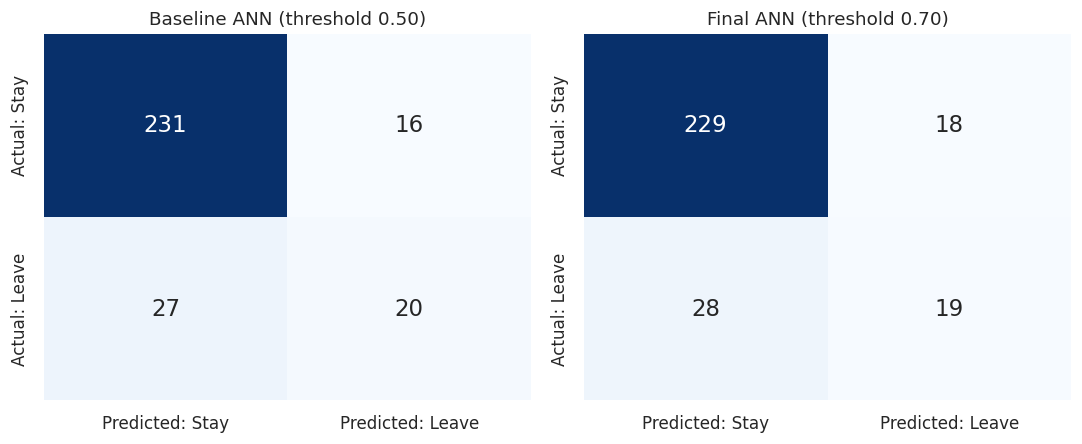

              precision    recall  f1-score   support

        Stay      0.891     0.927     0.909       247
       Leave      0.514     0.404     0.452        47

    accuracy                          0.844       294
   macro avg      0.702     0.666     0.681       294
weighted avg      0.831     0.844     0.836       294



In [17]:
# Figure: confusion matrices (baseline @0.5 vs final @tuned threshold)
cm_b = confusion_matrix(yte, (store[v0][SEED]["test"] >= 0.5).astype(int))
cm_f = confusion_matrix(yte, (final_prob_te >= THR).astype(int))
R["cm"] = {"baseline": cm_b.tolist(), "final": cm_f.tolist()}
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, cm, title in zip(axes, [cm_b, cm_f], ["Baseline ANN (threshold 0.50)", f"Final ANN (threshold {THR:.2f})"]):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, annot_kws={"size": 15},
                xticklabels=["Predicted: Stay", "Predicted: Leave"], yticklabels=["Actual: Stay", "Actual: Leave"])
    ax.set_title(title)
plt.tight_layout(); plt.savefig("figures/fig_confusion.png"); plt.show()
print(classification_report(yte, (final_prob_te >= THR).astype(int), target_names=["Stay", "Leave"], digits=3))

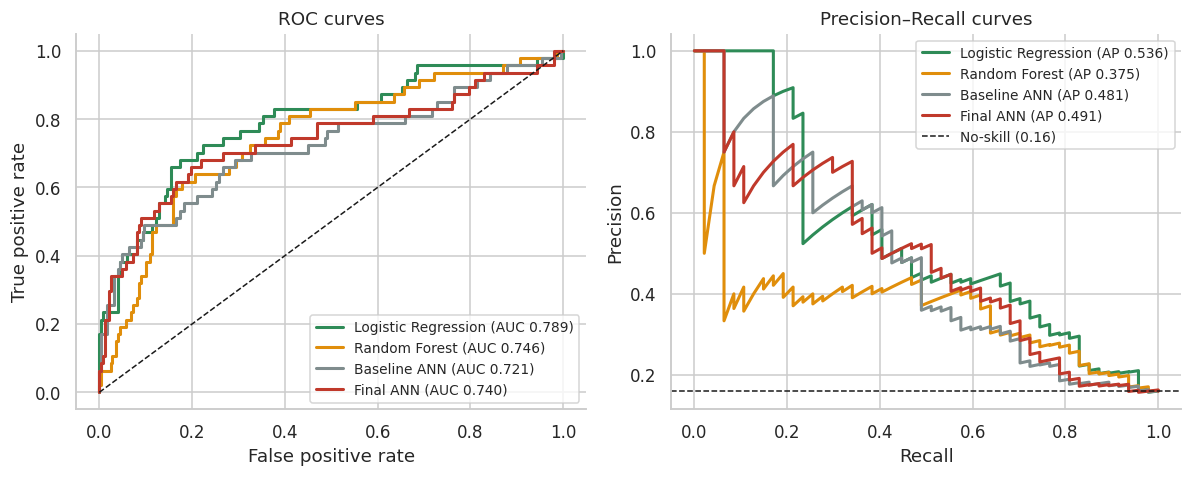

In [18]:
# Figure: ROC and Precision-Recall curves (test set, seed 42 / deterministic models)
rf42 = rf_store[SEED][1]
curves = {"Logistic Regression": (lr_test, GREEN), "Random Forest": (rf42, ORANGE),
          "Baseline ANN": (store[v0][SEED]["test"], GREY), "Final ANN": (final_prob_te, RED)}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for name, (p, c) in curves.items():
    fpr, tpr, _ = roc_curve(yte, p); axes[0].plot(fpr, tpr, color=c, lw=2, label=f"{name} (AUC {roc_auc_score(yte, p):.3f})")
    pr, rc, _ = precision_recall_curve(yte, p); axes[1].plot(rc, pr, color=c, lw=2, label=f"{name} (AP {average_precision_score(yte, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curves"); axes[0].legend(loc="lower right", fontsize=9)
axes[1].axhline(yte.mean(), color="k", ls="--", lw=1, label=f"No-skill ({yte.mean():.2f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision–Recall curves")
axes[1].legend(loc="upper right", fontsize=9)
plt.tight_layout(); plt.savefig("figures/fig_roc_pr.png"); plt.show()

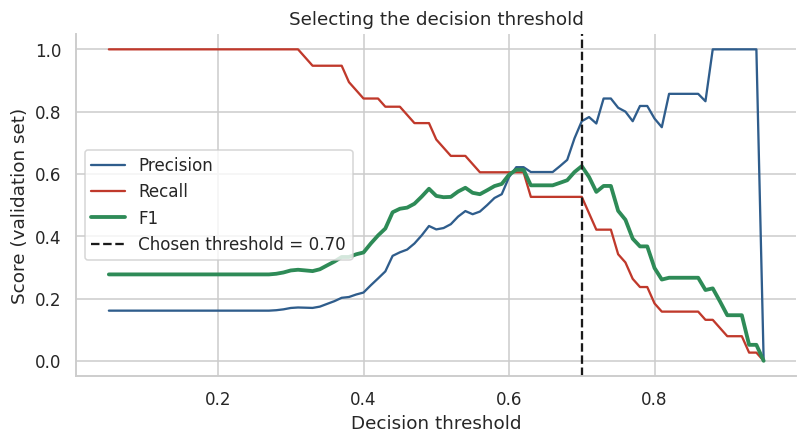

In [19]:
# Figure: threshold selection on validation set
thr, grid_t, f1s = best_threshold(yva, final_prob_val)
prec = [precision_score(yva, (final_prob_val >= t).astype(int), zero_division=0) for t in grid_t]
rec = [recall_score(yva, (final_prob_val >= t).astype(int)) for t in grid_t]
plt.figure(figsize=(7.5, 4.2))
plt.plot(grid_t, prec, color=BLUE, label="Precision"); plt.plot(grid_t, rec, color=RED, label="Recall")
plt.plot(grid_t, f1s, color=GREEN, lw=2.5, label="F1")
plt.axvline(thr, color="k", ls="--", label=f"Chosen threshold = {thr:.2f}")
plt.xlabel("Decision threshold"); plt.ylabel("Score (validation set)"); plt.title("Selecting the decision threshold")
plt.legend(); plt.tight_layout(); plt.savefig("figures/fig_threshold.png"); plt.show()

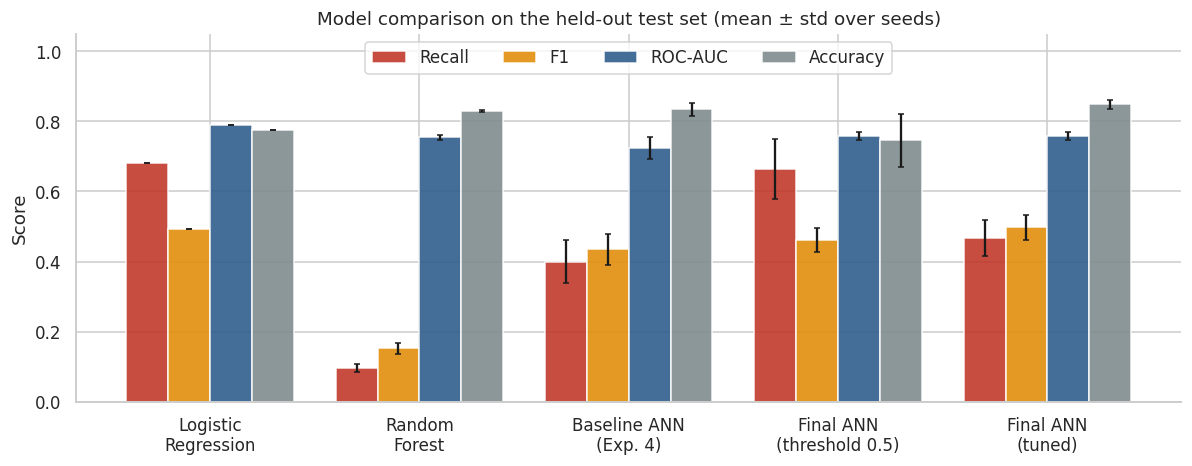

In [20]:
# Figure: model comparison (test set)
names = ["Logistic\nRegression", "Random\nForest", "Baseline ANN\n(Exp. 4)", "Final ANN\n(threshold 0.5)", "Final ANN\n(tuned)"]
keys = ["Logistic Regression", "Random Forest", "Baseline ANN (Exp. 4 setup)", "Final ANN (V3, threshold 0.5)", "Final ANN (V4, tuned threshold)"]
fig, ax = plt.subplots(figsize=(11, 4.4))
w = 0.2
for j, (m, lab, c) in enumerate([("recall", "Recall", RED), ("f1", "F1", ORANGE), ("roc_auc", "ROC-AUC", BLUE), ("accuracy", "Accuracy", GREY)]):
    vals = [comparison[k][m][0] for k in keys]; errs = [comparison[k][m][1] for k in keys]
    ax.bar(np.arange(5) + (j - 1.5) * w, vals, w, yerr=errs, capsize=2, label=lab, color=c, alpha=0.9)
ax.set_xticks(range(5)); ax.set_xticklabels(names); ax.set_ylim(0, 1.05); ax.set_ylabel("Score")
ax.set_title("Model comparison on the held-out test set (mean ± std over seeds)"); ax.legend(ncol=4, loc="upper center")
plt.tight_layout(); plt.savefig("figures/fig_model_comparison.png"); plt.show()

## 10. Explaining the ANN: permutation feature importance
Each feature of the test set is randomly shuffled (20 repeats); the resulting **drop in ROC-AUC** shows how
much the network relies on that feature.

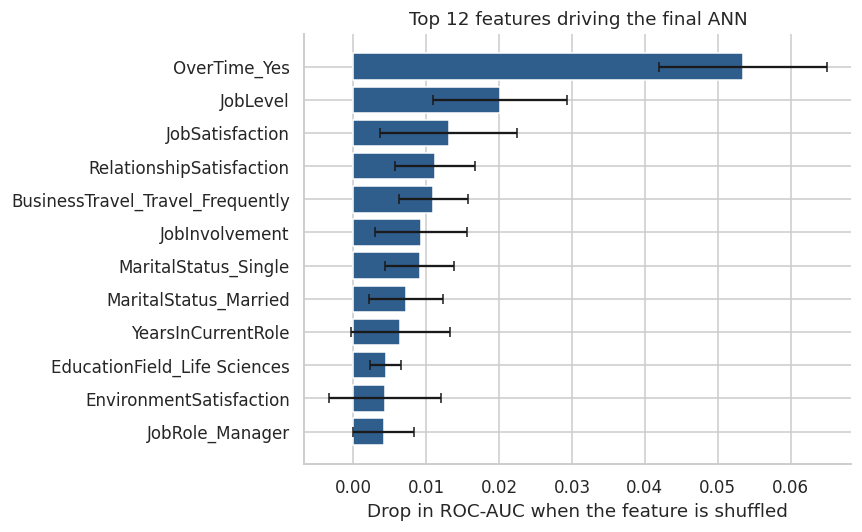

{'base_auc': 0.7402, 'top': [('OverTime_Yes', 0.0534), ('JobLevel', 0.0201), ('JobSatisfaction', 0.0131), ('RelationshipSatisfaction', 0.0112), ('BusinessTravel_Travel_Frequently', 0.011), ('JobInvolvement', 0.0093), ('MaritalStatus_Single', 0.0091), ('MaritalStatus_Married', 0.0072), ('YearsInCurrentRole', 0.0065), ('EducationField_Life Sciences', 0.0045), ('EnvironmentSatisfaction', 0.0044), ('JobRole_Manager', 0.0042)]}


In [21]:
def perm_importance(model, Xs, ys, names, reps=20, seed=0):
    rng = np.random.default_rng(seed)
    base = roc_auc_score(ys, model(Xs, training=False).numpy().ravel())
    out = []
    for j in range(Xs.shape[1]):
        batch = np.repeat(Xs[None, :, :], reps, axis=0).copy()
        for r in range(reps):
            batch[r, :, j] = rng.permutation(Xs[:, j])
        p = model(batch.reshape(-1, Xs.shape[1]), training=False).numpy().ravel().reshape(reps, -1)
        drops = [base - roc_auc_score(ys, p[r]) for r in range(reps)]
        out.append((names[j], np.mean(drops), np.std(drops)))
    return base, pd.DataFrame(out, columns=["feature", "auc_drop", "std"]).sort_values("auc_drop", ascending=False)

base_auc, imp = perm_importance(final_model, Xte, yte, X.columns.tolist())
top12 = imp.head(12).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top12["feature"], top12["auc_drop"], xerr=top12["std"], color=BLUE, capsize=3)
plt.xlabel("Drop in ROC-AUC when the feature is shuffled"); plt.title("Top 12 features driving the final ANN")
plt.tight_layout(); plt.savefig("figures/fig_importance.png"); plt.show()
R["importance"] = {"base_auc": round(float(base_auc), 4),
                   "top": [(r.feature, round(float(r.auc_drop), 4)) for r in imp.head(12).itertuples()]}
print(R["importance"])
imp.to_csv("outputs/permutation_importance.csv", index=False)

## 11. Error analysis on the test set

In [22]:
pred_final = (final_prob_te >= THR).astype(int)
ea = X_te[["OverTime_Yes"]].copy(); ea["actual"] = yte; ea["pred"] = pred_final
ea_rows = {}
for name, g in [("OverTime = Yes", ea[ea.OverTime_Yes == 1]), ("OverTime = No", ea[ea.OverTime_Yes == 0]), ("All employees", ea)]:
    tp = int(((g.actual == 1) & (g.pred == 1)).sum()); fn = int(((g.actual == 1) & (g.pred == 0)).sum())
    fp = int(((g.actual == 0) & (g.pred == 1)).sum()); tn = int(((g.actual == 0) & (g.pred == 0)).sum())
    ea_rows[name] = dict(n=len(g), leavers=tp + fn, caught=tp, missed=fn, false_alarms=fp,
                         recall=round(tp / (tp + fn), 3) if tp + fn else None)
R["error_analysis"] = ea_rows
display(pd.DataFrame(ea_rows).T)

,n,leavers,caught,missed,false_alarms,recall
OverTime = Yes,76.0,30.0,14.0,16.0,3.0,0.467
OverTime = No,218.0,17.0,5.0,12.0,15.0,0.294
All employees,294.0,47.0,19.0,28.0,18.0,0.404


## 12. Prediction demonstration and saving the model

In [23]:
def predict_attrition(row_df, model=final_model, scaler=scaler, threshold=THR):
    """row_df: one-row DataFrame with the same columns as X (after one-hot encoding)."""
    x = scaler.transform(row_df[X.columns]).astype("float32")
    p = float(model(x, training=False).numpy().ravel()[0])
    return p, ("HIGH RISK of leaving" if p >= threshold else "Likely to stay")

demo = []
for i in [int(np.where(yte == 1)[0][0]), int(np.where(yte == 0)[0][0]), int(np.where(yte == 1)[0][5])]:
    p, label = predict_attrition(X_te.iloc[[i]])
    demo.append(dict(test_row=i, actual="Left" if yte[i] else "Stayed", probability=round(p, 3), decision=label))
demo = pd.DataFrame(demo); display(demo); R["demo"] = demo.to_dict(orient="records")

final_model.save("models/final_ann_attrition.keras")
joblib.dump(scaler, "models/scaler.joblib")
json.dump({"features": X.columns.tolist(), "threshold": THR}, open("models/model_config.json", "w"), indent=2)
print("Saved model, scaler and config.")

,test_row,actual,probability,decision
0,4,Left,0.491,Likely to stay
1,0,Stayed,0.714,HIGH RISK of leaving
2,35,Left,0.744,HIGH RISK of leaving


Saved model, scaler and config.


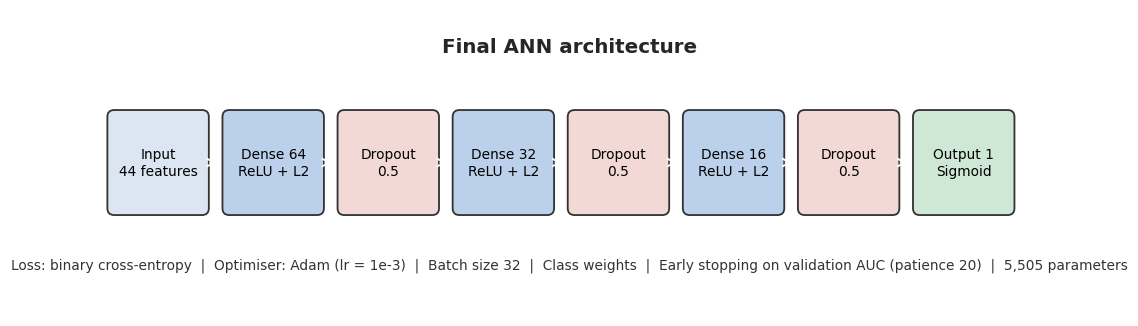

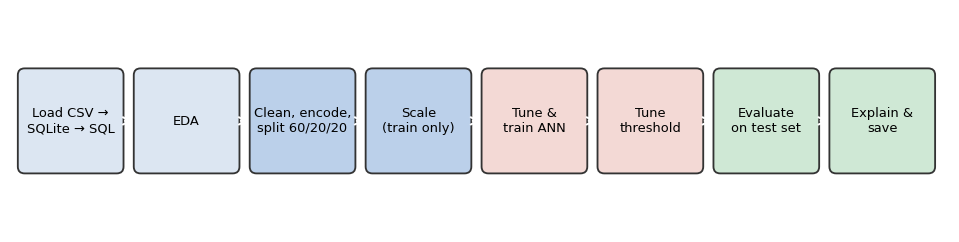

In [24]:
# Diagram figures for the report (architecture + workflow), drawn with matplotlib
def box(ax, x, y, w, h, text, fc, ec="#333", fs=9, tc="black"):
    ax.add_patch(mpatches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=fc, ec=ec, lw=1.2))
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=fs, color=tc)

fig, ax = plt.subplots(figsize=(11, 3.6)); ax.set_xlim(0, 11); ax.set_ylim(0, 3.6); ax.axis("off")
spec = [(f"Input\n{D} features", "#DCE6F2"),
        (f"Dense {BEST_UNITS[0]}\nReLU + L2", "#BBD0EA"), ("Dropout\n" + f"{BEST_DROP}", "#F3D9D5"),
        (f"Dense {BEST_UNITS[1]}\nReLU + L2", "#BBD0EA"), ("Dropout\n" + f"{BEST_DROP}", "#F3D9D5"),
        (f"Dense {BEST_UNITS[2]}\nReLU + L2", "#BBD0EA"), ("Dropout\n" + f"{BEST_DROP}", "#F3D9D5"),
        ("Output 1\nSigmoid", "#CFE8D5")]
x = 0.1
for i, (t, c) in enumerate(spec):
    box(ax, x, 1.2, 1.15, 1.2, t, c)
    if i < len(spec) - 1:
        ax.annotate("", xy=(x + 1.3, 1.8), xytext=(x + 1.15, 1.8), arrowprops=dict(arrowstyle="->", lw=1.3))
    x += 1.35
ax.text(5.5, 3.1, "Final ANN architecture", ha="center", fontsize=13, fontweight="bold")
ax.text(5.5, 0.55, f"Loss: binary cross-entropy  |  Optimiser: Adam (lr = 1e-3)  |  Batch size 32  |  "
        f"Class weights  |  Early stopping on validation AUC (patience 20)  |  {fm_params:,} parameters",
        ha="center", fontsize=9, color="#333")
plt.savefig("figures/fig_architecture.png"); plt.show()

fig, ax = plt.subplots(figsize=(11, 2.6)); ax.set_xlim(0, 11); ax.set_ylim(0, 2.6); ax.axis("off")
steps = ["Load CSV →\nSQLite → SQL", "EDA", "Clean, encode,\nsplit 60/20/20", "Scale\n(train only)", "Tune &\ntrain ANN",
         "Tune\nthreshold", "Evaluate\non test set", "Explain &\nsave"]
cols = ["#DCE6F2", "#DCE6F2", "#BBD0EA", "#BBD0EA", "#F3D9D5", "#F3D9D5", "#CFE8D5", "#CFE8D5"]
x = 0.1
for i, (t, c) in enumerate(zip(steps, cols)):
    box(ax, x, 0.7, 1.2, 1.2, t, c, fs=8.5)
    if i < len(steps) - 1:
        ax.annotate("", xy=(x + 1.36, 1.3), xytext=(x + 1.2, 1.3), arrowprops=dict(arrowstyle="->", lw=1.3))
    x += 1.36
plt.savefig("figures/fig_workflow.png"); plt.show()

In [25]:
json.dump(R, open("outputs/results.json", "w"), indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("All results saved to outputs/results.json")

All results saved to outputs/results.json


## 13. Statistical uncertainty: bootstrap comparison of the final ANN and Logistic Regression
The test set has only 47 leavers, so differences between models can be within sampling noise. 2,000 bootstrap resamples give 95% confidence intervals.

In [1]:
import json, numpy as np, pandas as pd, joblib
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, f1_score
cfg = json.load(open("models/model_config.json")); sc = joblib.load("models/scaler.joblib")
_raw = pd.read_csv("data/WA_Fn-UseC_-HR-Employee-Attrition.csv", encoding="utf-8-sig")
_y = (_raw.pop("Attrition") == "Yes").astype(int)
_raw = _raw.drop(columns=["EmployeeCount", "Over18", "StandardHours", "EmployeeNumber"])
_X = pd.get_dummies(_raw, drop_first=True).astype(float)[cfg["features"]]
_a, _Xte, _b, _yte = train_test_split(_X, _y, test_size=0.20, random_state=42, stratify=_y)
_Xtr, _Xva, _ytr, _yva = train_test_split(_a, _b, test_size=0.20, random_state=42, stratify=_b)
_Xtr, _Xte = sc.transform(_Xtr).astype("float32"), sc.transform(_Xte).astype("float32")
ann = keras.models.load_model("models/final_ann_attrition.keras")
p_ann = ann(_Xte, training=False).numpy().ravel()
lr_ = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42).fit(_Xtr, _ytr)
p_lr = lr_.predict_proba(_Xte)[:, 1]
yt = _yte.values; thr = cfg["threshold"]; rng = np.random.default_rng(0)
res = {"auc_ann": [], "auc_lr": [], "f1_ann": [], "f1_lr": []}
for _ in range(2000):
    i = rng.integers(0, len(yt), len(yt))
    if yt[i].sum() == 0: continue
    res["auc_ann"].append(roc_auc_score(yt[i], p_ann[i])); res["auc_lr"].append(roc_auc_score(yt[i], p_lr[i]))
    res["f1_ann"].append(f1_score(yt[i], p_ann[i] >= thr)); res["f1_lr"].append(f1_score(yt[i], p_lr[i] >= thr))
ci = lambda a: [round(float(np.percentile(a, 2.5)), 3), round(float(np.percentile(a, 97.5)), 3)]
B = {"auc_ann": [round(float(roc_auc_score(yt, p_ann)), 3)] + ci(res["auc_ann"]),
     "auc_lr": [round(float(roc_auc_score(yt, p_lr)), 3)] + ci(res["auc_lr"]),
     "auc_diff_ann_minus_lr": ci(np.array(res["auc_ann"]) - np.array(res["auc_lr"])),
     "f1_ann": [round(float(f1_score(yt, p_ann >= thr)), 3)] + ci(res["f1_ann"]),
     "f1_lr": [round(float(f1_score(yt, p_lr >= thr)), 3)] + ci(res["f1_lr"]),
     "f1_diff_ann_minus_lr": ci(np.array(res["f1_ann"]) - np.array(res["f1_lr"]))}
json.dump(B, open("outputs/bootstrap.json", "w"), indent=2); print(json.dumps(B, indent=1))


I0000 00:00:1792839839.386520      83 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792839839.391481      83 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792839855.339752      83 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1792839864.181243      83 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792839864.185128      83 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


E0000 00:00:1792839867.321110      83 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


{
 "auc_ann": [
  0.74,
  0.642,
  0.826
 ],
 "auc_lr": [
  0.789,
  0.706,
  0.862
 ],
 "auc_diff_ann_minus_lr": [
  -0.114,
  0.006
 ],
 "f1_ann": [
  0.452,
  0.298,
  0.575
 ],
 "f1_lr": [
  0.469,
  0.333,
  0.583
 ],
 "f1_diff_ann_minus_lr": [
  -0.124,
  0.087
 ]
}
